# DP Plots

This notebook provides visualizations for the tradeoff between AUC and noise levels.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
filenames = [
    "../data/tables/summary_sepsis_dpsgd.csv",
]
df = pd.concat([pd.read_csv(filename, header=[0,1,2]) for filename in filenames])

df.head()

Unnamed: 0_level_0 Unnamed: 1_level_0 Unnamed: 2_level_0  \
  Unnamed: 0_level_1 Unnamed: 1_level_1 Unnamed: 2_level_1   
     N. Trajectories         Ensemble k   Ensemble epsilon   
0                100                  1                1.0   
1                100                  1               10.0   
2                100                  1              100.0   
3                100                  1             1000.0   
4                100                  1            10000.0   

  Trainer Mean Reward                              Accuracy  \
                 mean                std               mean   
   Unnamed: 3_level_2 Unnamed: 4_level_2 Unnamed: 5_level_2   
0              0.7711             0.0324             0.4956   
1              0.7775             0.0262             0.4982   
2              0.7783             0.0282             0.5088   
3              0.7731             0.0317             0.5688   
4              0.7709             0.0381             0.6182   

                              Precision                                Recall  \
                 std               mean                std               mean   
  Unnamed: 6_level_2 Unnamed: 7_level_2 Unnamed: 8_level_2 Unnamed: 9_level_2   
0             0.0528             0.4973             0.0325             0.8248   
1             0.0531             0.4988             0.0326             0.8296   
2             0.0502             0.5051             0.0308             0.8444   
3             0.0444             0.5447             0.0320             0.8940   
4             0.0745             0.5880             0.0651             0.8784   

   ...        TPR@0.001FPR                            TPR@0.005FPR  \
   ...                mean                 std                mean   
   ... Unnamed: 13_level_2 Unnamed: 14_level_2 Unnamed: 15_level_2   
0  ...              0.0180              0.0203              0.0181   
1  ...              0.0188              0.0260              0.0189   
2  ...              0.0188              0.0275              0.0189   
3  ...              0.0272              0.0437              0.0274   
4  ...              0.0365              0.0657              0.0367   

                              TPR@0.01FPR                      \
                  std                mean                 std   
  Unnamed: 16_level_2 Unnamed: 17_level_2 Unnamed: 18_level_2   
0              0.0202              0.0182              0.0202   
1              0.0259              0.0190              0.0259   
2              0.0275              0.0190              0.0274   
3              0.0437              0.0276              0.0437   
4              0.0657              0.0370              0.0656   

          TPR@0.05FPR                              TPR@0.1FPR  \
                 mean                 std                mean   
  Unnamed: 19_level_2 Unnamed: 20_level_2 Unnamed: 21_level_2   
0              0.0580              0.0396              0.1144   
1              0.0600              0.0455              0.1168   
2              0.0584              0.0503              0.1328   
3              0.0888              0.0834              0.2236   
4              0.1214              0.1040              0.2448   

                       
                  std  
  Unnamed: 22_level_2  
0              0.0616  
1              0.0616  
2              0.0703  
3              0.1221  
4              0.1316  

[5 rows x 23 columns]

In [3]:
df_hierarchical = df.iloc[:, 3:]
df_hierarchical.columns = df_hierarchical.columns.droplevel(2)
df_hierarchical.columns = [f'{col[0]} ({col[1]})' for col in df_hierarchical.columns]
df_hierarchical.head()

,Trainer Mean Reward (mean),Trainer Mean Reward (std),Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),AUC (mean),AUC (std),TPR@0.001FPR (mean),TPR@0.001FPR (std),TPR@0.005FPR (mean),TPR@0.005FPR (std),TPR@0.01FPR (mean),TPR@0.01FPR (std),TPR@0.05FPR (mean),TPR@0.05FPR (std),TPR@0.1FPR (mean),TPR@0.1FPR (std)
0,0.7711,0.0324,0.4956,0.0528,0.4973,0.0325,0.8248,0.0677,0.4934,0.0658,0.0180,0.0203,0.0181,0.0202,0.0182,0.0202,0.0580,0.0396,0.1144,0.0616
1,0.7775,0.0262,0.4982,0.0531,0.4988,0.0326,0.8296,0.0662,0.4980,0.0662,0.0188,0.0260,0.0189,0.0259,0.0190,0.0259,0.0600,0.0455,0.1168,0.0616
2,0.7783,0.0282,0.5088,0.0502,0.5051,0.0308,0.8444,0.0719,0.5230,0.0644,0.0188,0.0275,0.0189,0.0275,0.0190,0.0274,0.0584,0.0503,0.1328,0.0703
3,0.7731,0.0317,0.5688,0.0444,0.5447,0.0320,0.8940,0.1030,0.6536,0.0676,0.0272,0.0437,0.0274,0.0437,0.0276,0.0437,0.0888,0.0834,0.2236,0.1221
4,0.7709,0.0381,0.6182,0.0745,0.5880,0.0651,0.8784,0.1043,0.7054,0.0689,0.0365,0.0657,0.0367,0.0657,0.0370,0.0656,0.1214,0.1040,0.2448,0.1316


In [4]:
df_groups = df.iloc[:, :3]
for _ in range(2):
    df_groups.columns = df_groups.columns.droplevel(0)
df_groups.head()

,N. Trajectories,Ensemble k,Ensemble epsilon
0,100,1,1.0
1,100,1,10.0
2,100,1,100.0
3,100,1,1000.0
4,100,1,10000.0


In [5]:
df_clean = pd.concat([df_groups, df_hierarchical], axis=1)
df_clean = df_clean.sort_values(by=["N. Trajectories", "Ensemble k"])
df_clean.head()

,N. Trajectories,Ensemble k,Ensemble epsilon,Trainer Mean Reward (mean),Trainer Mean Reward (std),Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),...,TPR@0.001FPR (mean),TPR@0.001FPR (std),TPR@0.005FPR (mean),TPR@0.005FPR (std),TPR@0.01FPR (mean),TPR@0.01FPR (std),TPR@0.05FPR (mean),TPR@0.05FPR (std),TPR@0.1FPR (mean),TPR@0.1FPR (std)
0,100,1,1.0,0.7711,0.0324,0.4956,0.0528,0.4973,0.0325,0.8248,...,0.0180,0.0203,0.0181,0.0202,0.0182,0.0202,0.0580,0.0396,0.1144,0.0616
1,100,1,10.0,0.7775,0.0262,0.4982,0.0531,0.4988,0.0326,0.8296,...,0.0188,0.0260,0.0189,0.0259,0.0190,0.0259,0.0600,0.0455,0.1168,0.0616
2,100,1,100.0,0.7783,0.0282,0.5088,0.0502,0.5051,0.0308,0.8444,...,0.0188,0.0275,0.0189,0.0275,0.0190,0.0274,0.0584,0.0503,0.1328,0.0703
3,100,1,1000.0,0.7731,0.0317,0.5688,0.0444,0.5447,0.0320,0.8940,...,0.0272,0.0437,0.0274,0.0437,0.0276,0.0437,0.0888,0.0834,0.2236,0.1221
4,100,1,10000.0,0.7709,0.0381,0.6182,0.0745,0.5880,0.0651,0.8784,...,0.0365,0.0657,0.0367,0.0657,0.0370,0.0656,0.1214,0.1040,0.2448,0.1316


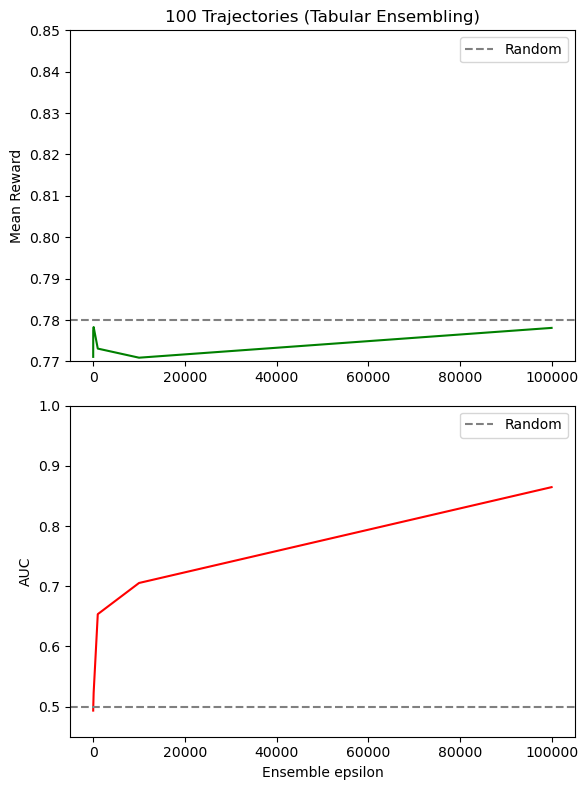

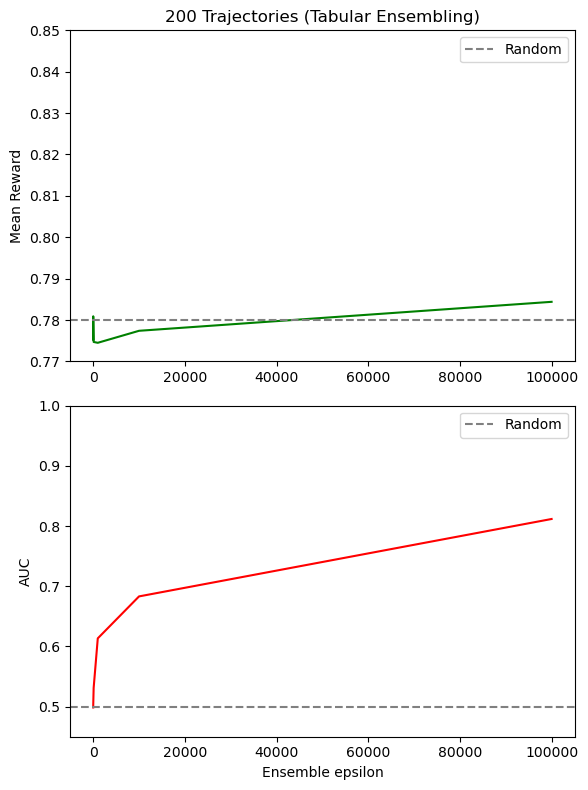

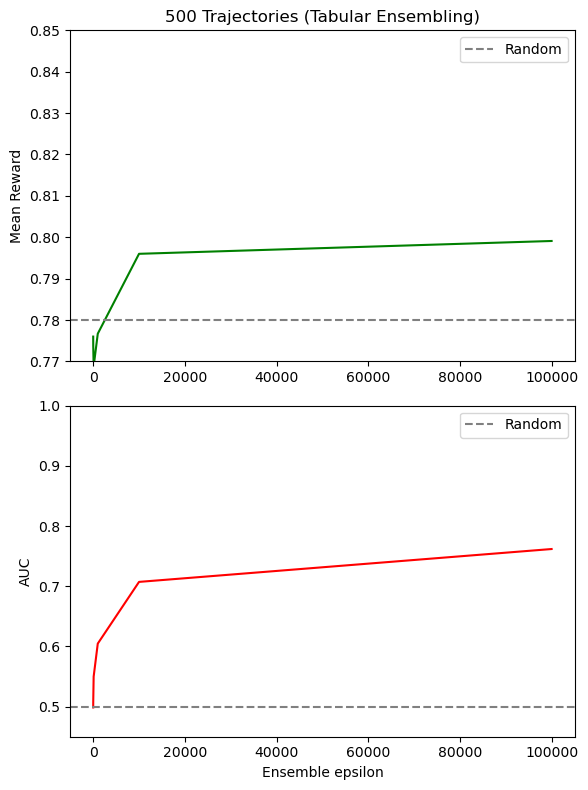

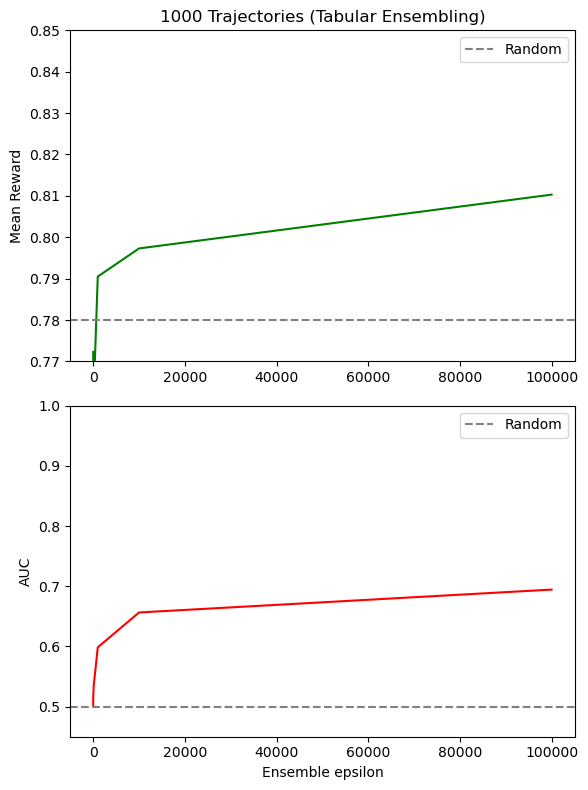

In [6]:
# Plot reward vs input (ensemble k or perturbation std or epsilon) for particular n. trajs
n_trajs = df_clean["N. Trajectories"].unique()

k = 50
epsilon = 3000

inpt = "Ensemble epsilon"
context = "Tabular Ensembling"

for n_traj in n_trajs:
    #group = df_clean[(df_clean["N. Trajectories"] == n_traj) & (df_clean["Ensemble k"] == k)]
    #group = df_clean[(df_clean["N. Trajectories"] == n_traj) & (df_clean["Ensemble epsilon"] == epsilon)]
    group = df_clean[(df_clean["N. Trajectories"] == n_traj)]
    
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(6, 8))
    
    # Rewards
    ax1.plot(group[inpt], group["Trainer Mean Reward (mean)"], color="green")
    ax1.set_ylim([0.77, 0.85])
    ax1.set_ylabel("Mean Reward")
    ax1.axhline(0.78, color="gray", linestyle="--", label="Random")
    ax1.set_title(f"{n_traj} Trajectories ({context})")
    ax1.legend()
    
    # Rewards
    ax2.plot(group[inpt], group["AUC (mean)"], color="red")
    ax2.set_ylim([0.45, 1.0])
    ax2.set_xlabel(inpt)
    ax2.set_ylabel("AUC")
    ax2.axhline(0.5, color="gray", linestyle="--", label="Random")
    ax2.legend()

    plt.tight_layout()
    plt.show()

    

## Stacked AUC and return vs. epsilon

AUC (left) and trainer return (right) against the privacy budget for several mechanisms at one $n$, one row per mechanism, on a shared, log-scaled $\varepsilon$ axis. Read from the raw results (one row per run), with 95% confidence bands. Dashed lines mark the mechanism without noise ($\varepsilon = \infty$; for the ensemble, still averaged and clipped) and a random guess (AUC 0.5) or random policy (return).

In [7]:
import os
import numpy as np
from scipy import stats


def metric_by_epsilon(name, n, k=1, metric="AUC"):
    """Mean and 95% CI half-width of a metric per epsilon (inf = non-private) from data/tables/hyperparam_results_{name}.csv."""
    d = pd.read_csv(f"../data/tables/hyperparam_results_{name}.csv")
    d = d[(d["N. Trajectories"] == n) & (d["Ensemble k"] == k)]
    g = d.groupby(d["Ensemble epsilon"].fillna(np.inf))[metric]
    ci = g.agg(lambda x: stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)))
    return pd.DataFrame({"mean": g.mean(), "ci": ci, "runs": g.size()})


def _plot_metric(ax, t, color, reference, reference_label, ylim, ylabel):
    """One metric against epsilon on ax, with its CI band, non-private line, and reference line."""
    private = t[np.isfinite(t.index)]
    ax.plot(private.index, private["mean"], color=color, marker="o", markersize=4)
    ax.fill_between(private.index, private["mean"] - private["ci"], private["mean"] + private["ci"],
                    color=color, alpha=0.2, linewidth=0)
    if np.inf in t.index:
        ax.axhline(t.loc[np.inf, "mean"], color="black", linestyle="--", linewidth=1, label=r"No noise ($\varepsilon = \infty$)")
    ax.axhline(reference, color="gray", linestyle="--", linewidth=1, label=reference_label)
    ax.set_xscale("log")
    ax.set_ylim(ylim)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best", fontsize=8)


def stacked_auc_vs_epsilon(panels, n, random_return, title=None, filename=None,
                           auc_ylim=(0.45, 1.0), return_ylim=(0.76, 0.85)):
    """
    panels: list of (label, results name, k). One row per entry, with AUC (left) and trainer
    return (right) against epsilon; all panels share the epsilon axis. random_return is the
    environment's random-policy return, drawn as the return panels' reference line.
    """
    fig, axes = plt.subplots(len(panels), 2, figsize=(11, 2.8 * len(panels)), sharex=True, squeeze=False)
    for row, (label, name, k) in zip(axes, panels):
        _plot_metric(row[0], metric_by_epsilon(name, n, k, "AUC"), "red", 0.5, "Random guess", auc_ylim, "AUC")
        _plot_metric(row[1], metric_by_epsilon(name, n, k, "Trainer Mean Reward"), "green",
                     random_return, "Random policy", return_ylim, "Return")
        row[0].set_title(f"{label}: AUC")
        row[1].set_title(f"{label}: return")
    for ax in axes[-1]:
        ax.set_xlabel(r"Privacy budget $\varepsilon$")
    if title is not None:
        fig.suptitle(title)
    fig.tight_layout()
    if filename is not None:
        os.makedirs("../data/plots/auc_vs_epsilon", exist_ok=True)
        fig.savefig(f"../data/plots/auc_vs_epsilon/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

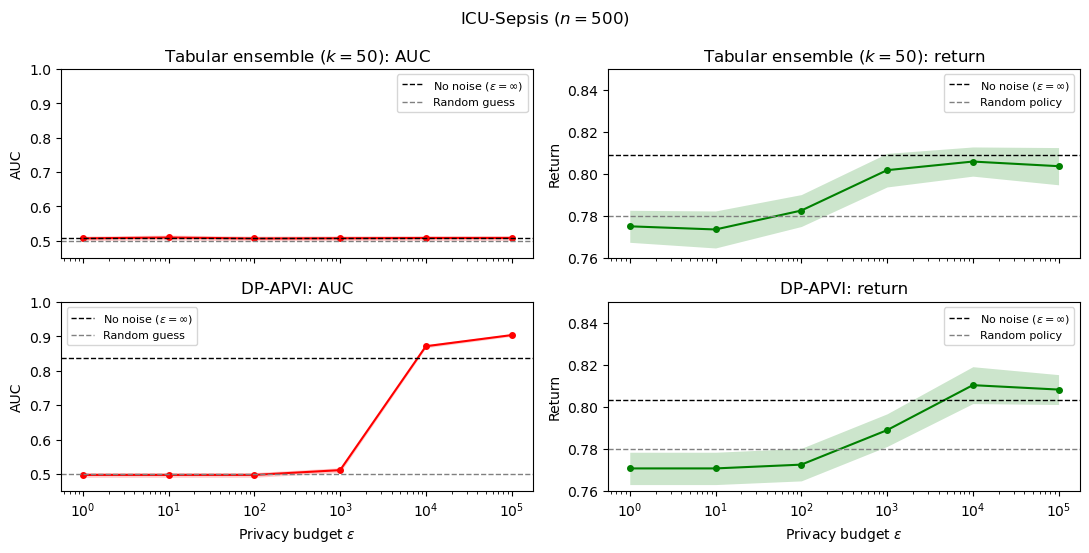

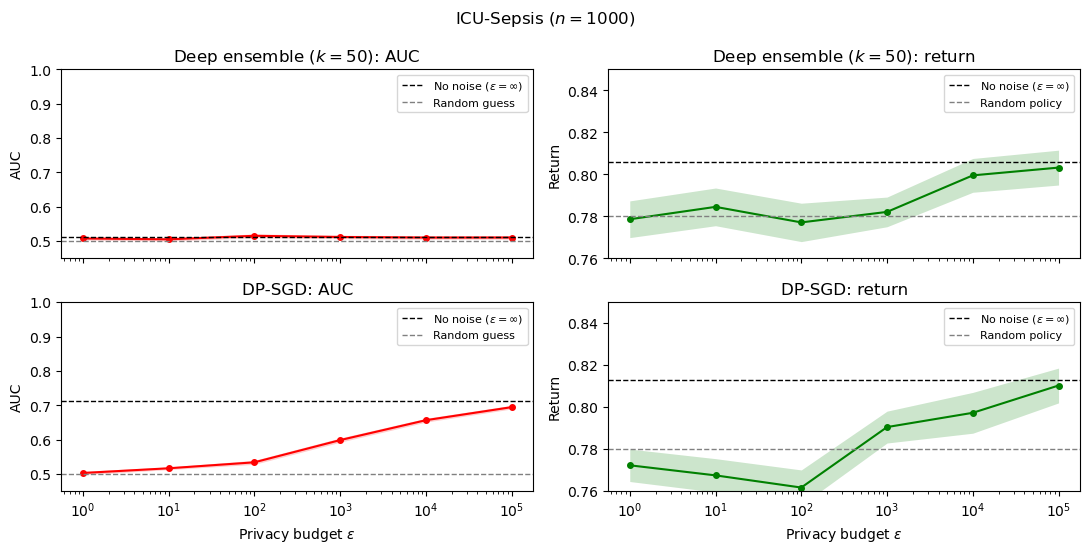

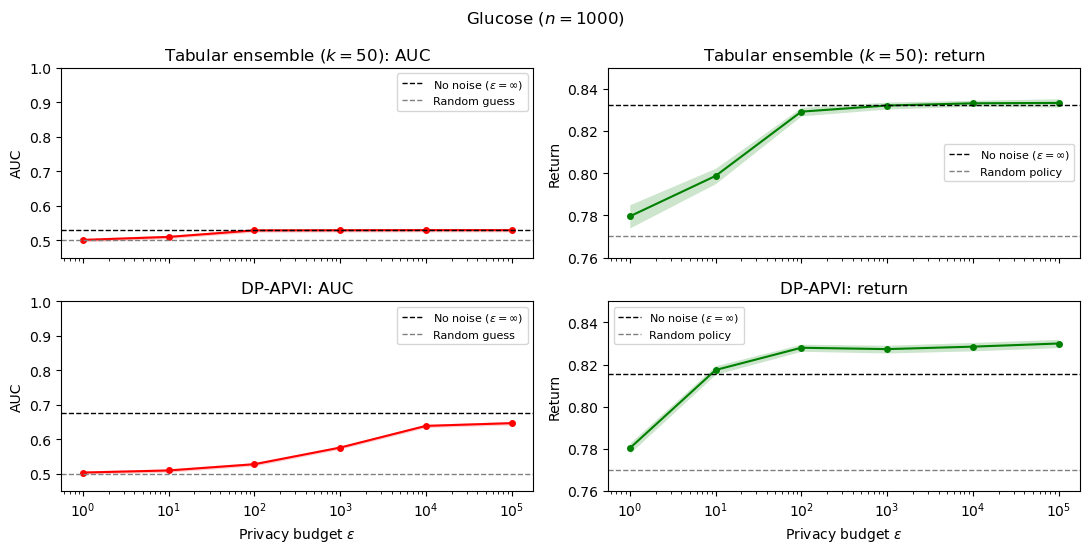

In [8]:
N, K = 500, 50  # every ensemble uses k = 50

stacked_auc_vs_epsilon(
    [(f"Tabular ensemble ($k = {K}$)", "sepsis_tabular_ensemble", K), ("DP-APVI", "sepsis_dpapvi", 1)],
    n=N, random_return=0.78, title=f"ICU-Sepsis ($n = {N}$)", filename=f"sepsis_ensemble_vs_dpapvi_n{N}.png",
)
N = 1000
stacked_auc_vs_epsilon(
    [(f"Deep ensemble ($k = {K}$)", "sepsis_cql_ensemble", K), ("DP-SGD", "sepsis_dpsgd", 1)],
    n=N, random_return=0.78, title=f"ICU-Sepsis ($n = {N}$)", filename=f"sepsis_ensemble_vs_dpsgd_n{N}.png",
)
stacked_auc_vs_epsilon(
    [(f"Tabular ensemble ($k = {K}$)", "glucose_tabular_ensemble", K), ("DP-APVI", "glucose_dpapvi", 1)],
    n=N, random_return=0.77, title=f"Glucose ($n = {N}$)", filename=f"glucose_ensemble_vs_dpapvi_n{N}.png",
)
